# Detection and calibration

Notebook 3 of 3, for *Faint Companions to Hot Stars*: §3, eqs. 15–19, Figs. 4–5,
App. C.2.

This is where the machinery of the first two notebooks turns into a decision.
Three questions, in order. How well can $\alpha$ be measured, as a function of
the separation $v$, in each channel? What is the null distribution of the
likelihood-ratio statistic when the companion amplitude cannot go negative? And
what happens to that null once $v$ is scanned rather than known — which is the
realistic case, and the one where a textbook threshold quietly stops being
correct.

The three sections share concepts but no variables; each one re-simulates its
own setup.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

try:
    import specbeat
except ModuleNotFoundError:
    # Source checkout without `pip install -e .`: add the package's src/ to the path.
    import sys
    from pathlib import Path
    for _p in [Path.cwd(), *Path.cwd().parents]:
        if (_p / "src" / "specbeat").is_dir():
            sys.path.insert(0, str(_p / "src"))
            break

from specbeat import simulate
from specbeat.plotting import set_paper_style, regime_label

set_paper_style()

{'font.family': 'sans-serif',
 'font.sans-serif': ['Helvetica', 'Arial', 'DejaVu Sans'],
 'font.size': 11.0,
 'axes.titlesize': 11.0,
 'axes.labelsize': 11.0,
 'xtick.labelsize': 10.0,
 'ytick.labelsize': 10.0,
 'legend.fontsize': 8.0,
 'axes.linewidth': 0.8,
 'xtick.major.width': 0.7,
 'ytick.major.width': 0.7,
 'xtick.direction': 'in',
 'ytick.direction': 'in',
 'lines.linewidth': 1.2,
 'figure.dpi': 110,
 'savefig.dpi': 300,
 'savefig.bbox': 'tight',
 'axes.grid': False}

## Sensitivity scalings

Both channels reduce to one quantity, the profiled Fisher information on
$\alpha$ (eq. C.10). With template $\mathbf t$, baseline design $M$, projector
$P$, and weights $W = \mathrm{diag}(|\tilde S_i|^2/\sigma_A^2)$,

$$I_\alpha = \mathbf r^\top W\,\mathbf r,\quad \mathbf r=(I-P)\,\mathbf t,
\qquad \sigma_\alpha = I_\alpha^{-1/2}.$$

The two channels differ only in what goes into $\mathbf t$ and $M$, and the
difference is large. In the amplitude channel $\mathbf t=\cos2\pi\zeta v$ and
$M=[1,\zeta,\zeta^2]$; the baseline absorbs the expansion through $\zeta^2$ and
the survivor goes as $\zeta^4v^4$, so (eq. 17)

$$\frac{\Delta\alpha}{\alpha} \propto \Big(\frac{v_G}{v}\Big)^{4}.$$

In the phase channel $\mathbf t=\sin2\pi\zeta v$ and there is no baseline at all
(`design=None`), so nothing is projected out:
$I_\alpha=\sum_i w_i\sin^2(2\pi\zeta_iv)\propto v^2$ at small $v$, and (eq. 18)

$$\frac{\Delta\alpha}{\alpha} \propto v^{-1}.$$

Four powers of $v$ separate them, and the whole difference is the baseline.

The cells below evaluate both curves absolutely, for one shared instrument, so
they can be compared on a single axis (cf. Fig. 4); check them against
Monte-Carlo fits on noisy composites at several $v$; and measure the log–log
slopes over the small-$v$ range, which should come out at $-4$ and $-1$. The
trial $v$ is fixed and known throughout, the pixel noise is white with a known
$\sigma_A$, and the phase channel gets its rest frame from outside.

In [2]:
from specbeat import amplitude, power, phase

# Deviation from the fiducial: the paper's own Fig. 3/4 parameters
# (LSF-limited pair, alpha = 0.25, sigma_pix = 0.015).
FIG4 = dict(wavelength_0=5875.6, line_depth=0.5, vG=20.0, gamma=5.0,
            vsini=0.0, epsilon=0.5)
dv, N = 1.0, 2048
sigma_pix, alpha0 = 0.015, 0.25
zeta_band = 0.02

wave = simulate.generate_wavelength_grid(FIG4["wavelength_0"], dv, N)
spec0, _, _ = simulate.generate_simulated_spectrum(wave, dv, v=0.0,
                                                   second_component=False, **FIG4)
spec0 = np.asarray(spec0, float)

zeta = np.fft.rfftfreq(N, d=dv)[1:]
band = zeta <= zeta_band
zf = zeta[band]
S0 = np.abs(np.fft.rfft(spec0))[1:][band]                 # single-star |S~|
sigma_A = amplitude.amp_noise_sigma(sigma_pix, n=N)
w = (S0 / sigma_A) ** 2                                   # shared weights
M_base = amplitude.construct_log_amp_model_matrix(zf, 0.0, n_cos_terms=None,
                                                  n_baseline=2)
x0 = np.interp(FIG4["wavelength_0"], wave, np.arange(N)) * dv

def dalpha_over_alpha(v):
    sa_amp = 1 / np.sqrt(power.fisher_information_alpha(
        np.cos(2 * np.pi * zf * v), M_base, w))
    sa_ph = 1 / np.sqrt(power.fisher_information_alpha(
        np.sin(2 * np.pi * zf * v), None, w))
    return sa_amp / alpha0, sa_ph / alpha0

In [3]:
# (2) MC dots: fit alpha on noisy composites, both channels, at four v.
def mc_scatter(v, n_draws=24):
    ah_amp, ah_ph = [], []
    M1 = amplitude.construct_log_amp_model_matrix(zf, v, n_cos_terms=0,
                                                  n_baseline=2)
    for s in range(n_draws):
        r = np.random.default_rng(3000 + s)
        sp, _, _ = simulate.generate_simulated_spectrum(
            wave, dv, v=0.0, second_component=True, v2=v, vG2=FIG4["vG"],
            gamma2=FIG4["gamma"], vsini2=FIG4["vsini"], epsilon2=FIG4["epsilon"],
            depth_ratio=alpha0, **FIG4)
        sp = np.asarray(sp, float) + r.normal(0, sigma_pix, N)
        a_n = np.abs(np.fft.rfft(sp))[1:][band]
        th, _, _ = amplitude.bounded_weighted_least_squares(
            M1, np.log(a_n), w, bounds=None)
        ah_amp.append(th[-1])
        f = phase.fit_phase_alpha(np.fft.rfft(sp)[1:][band], zf,
                                  rest_shift_kms=x0, dv_rel=v, sigma_ft=sigma_A)
        ah_ph.append(f["alpha_hat"])
    return np.std(ah_amp) / alpha0, np.std(ah_ph) / alpha0

v_mc = np.array([2.0, 5.0, 15.0, 40.0])
mc_amp, mc_ph = np.array([mc_scatter(v) for v in v_mc]).T

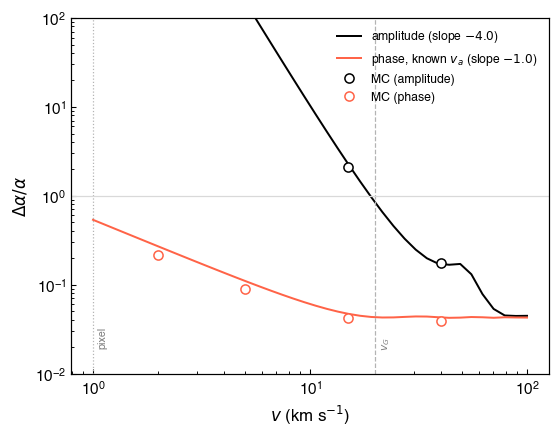

slopes over v <= 6 km/s:  amplitude -3.99 (eq. 17: -4),  phase -0.98 (eq. 18: -1)


In [4]:
# (1) + (3): absolute curves, MC dots, small-v slopes. cf. paper Fig. 4.
v_curve = np.geomspace(1.0, 100.0, 40)
curves = np.array([dalpha_over_alpha(v) for v in v_curve])

v_slope = v_curve[v_curve <= 6.0]
sl_amp = np.polyfit(np.log(v_slope),
                    np.log(curves[v_curve <= 6.0, 0]), 1)[0]
sl_ph = np.polyfit(np.log(v_slope),
                   np.log(curves[v_curve <= 6.0, 1]), 1)[0]

fig, ax = plt.subplots(figsize=(5.6, 4.2))
ax.loglog(v_curve, curves[:, 0], "k-", lw=1.3,
          label=fr"amplitude (slope ${sl_amp:.1f}$)")
ax.loglog(v_curve, curves[:, 1], "-", color="tomato", lw=1.3,
          label=fr"phase, known $v_a$ (slope ${sl_ph:.1f}$)")
ax.loglog(v_mc, mc_amp, "o", ms=6, mfc="white", mec="k", label="MC (amplitude)")
ax.loglog(v_mc, mc_ph, "o", ms=6, mfc="white", mec="tomato", label="MC (phase)")
ax.axvline(dv, color="0.7", ls=":", lw=0.8)
ax.axvline(FIG4["vG"], color="0.7", ls="--", lw=0.8)
ax.axhline(1.0, color="0.85", lw=0.8)
ax.text(dv * 1.05, 2e-2, "pixel", rotation=90, fontsize=7, color="0.5")
ax.text(FIG4["vG"] * 1.05, 2e-2, r"$v_G$", rotation=90, fontsize=7, color="0.5")
ax.set_xlabel(r"$v$ (km s$^{-1}$)")
ax.set_ylabel(r"$\Delta\alpha/\alpha$")
ax.set_ylim(1e-2, 1e2)
ax.legend(frameon=False, loc="upper right")
plt.show()
print(f"slopes over v <= 6 km/s:  amplitude {sl_amp:.2f} (eq. 17: -4),  "
     f"phase {sl_ph:.2f} (eq. 18: -1)")

The Monte-Carlo points track both analytic curves. $\Delta\alpha/\alpha\gtrsim1$
marks the practical non-detection regime; the amplitude channel crosses it near
$v\sim v_G$, while the phase channel stays usable well below. Above $v\sim v_G$
the two channels converge, because by then the baseline has nothing left to
absorb.

One caveat on eq. 18: the $v^{-1}$ law assumes the rest frame is known
externally, from an ephemeris or an independent line. Fit a velocity shift from
the same data instead and the leading term of the sine template is projected
out, leaving a markedly shallower scaling. `fisher_information_alpha` handles
that case through a shift column in `design`, and the test suite exercises it,
but it is not pursued here.

Everything above came from one formula, $I_\alpha=\mathbf r^\top W\mathbf r$
with $\mathbf r=(I-P)\mathbf t$. The exponent just counts the Taylor orders the
baseline swallows: $-4$ with a quadratic baseline, $-1$ with none.

## The detection statistic at fixed $v$

Now the decision. The likelihood-ratio statistic is the improvement in $\chi^2$
from allowing a companion,

$$T = \chi^2_{H_0} - \chi^2_{H_1}(v) \;\geq\; 0,$$

and its null distribution is not $\chi^2_1$. Because $\alpha$ is a line-depth
ratio it cannot be negative, so under $H_0$ the true value sits on the boundary
of the parameter space, and the standard asymptotics do not apply. What applies
instead is the Chernoff (1954) mixture,

$$T \,\big|\, H_0 \;\sim\; \tfrac12\,\delta_0 + \tfrac12\,\chi^2_1 .$$

The mechanism is simple enough to state in one sentence: under $H_0$ the
unconstrained $\hat\alpha$ is negative half the time, those trials are clamped
to the boundary, and they all contribute $T=0$ — which is the atom at zero.

Three numbers follow, and all three are commonly got wrong. The 5% threshold is
$\chi^2_1$'s 90% point, $c=2.706$, not 3.841. The p-value at $T\le0$ is 1, not
0.5. And the detection power takes the one-sided constrained form
$\bar\Phi(\sqrt c-\sqrt\lambda)$ with $\lambda=\alpha^2I_\alpha$.

The cells below check the atom weight and the false-alarm rate by simulation
before quoting the theorem, then compute the three numbers, then build upper
limits from the truncated-Gaussian posterior — which need the raw $\hat\alpha$,
including negative values, and a numerically stable form to survive them. The
model is linear here, the errors Gaussian with known scale, and $v$ is fixed.

In [5]:
from specbeat import nulls
from scipy.stats import chi2 as scipy_chi2, ncx2

# (1) Derive the "1/2" by simulation: pure H0 noise, both models fit at one
#     fixed v, UNCONSTRAINED baseline (the single-boundary setting of the
#     theorem; see Note below for the production pipeline's extra bound).
dv2, N2 = 1.0, 1024
z2 = np.fft.rfftfreq(N2, d=dv2)[1:]
z2 = z2[z2 <= 0.03]
M1 = amplitude.construct_log_amp_model_matrix(z2, 60.0, n_cos_terms=0, n_baseline=2)
M0 = amplitude.construct_log_amp_model_matrix(z2, 0.0, n_cos_terms=None, n_baseline=2)
w2 = np.ones(len(z2))

rng = np.random.default_rng(3)
n_trials = 4000
alpha_hats = np.empty(n_trials)
Ts = np.empty(n_trials)
for i in range(n_trials):
    y = rng.standard_normal(len(z2))
    th1, _, c1 = amplitude.bounded_weighted_least_squares(M1, y, w2, bounds=None)
    _, _, c0 = amplitude.bounded_weighted_least_squares(M0, y, w2, bounds=None)
    alpha_hats[i] = th1[-1]
    Ts[i] = max(0.0, c0 - c1) if th1[-1] >= 0.0 else 0.0

c = nulls.detection_threshold(fap=0.05, df=1)
print(f"P(alpha_hat < 0 | H0)      = {np.mean(alpha_hats < 0):.3f}   (Chernoff: 0.5)")
print(f"P(T = 0 | H0)              = {np.mean(Ts == 0):.3f}   (same trials)")
print(f"threshold c (fap = 0.05)   = {c:.3f}")
print(f"empirical P(T >= c | H0)   = {np.mean(Ts >= c):.4f}  (target 0.05)")

P(alpha_hat < 0 | H0)      = 0.502   (Chernoff: 0.5)
P(T = 0 | H0)              = 0.502   (same trials)
threshold c (fap = 0.05)   = 2.706
empirical P(T >= c | H0)   = 0.0508  (target 0.05)


One aside on the production pipeline. `specbeat.detect` also bounds the baseline
($a_1\le0$, $a_2\le0$: a physically decaying envelope), which is a second
boundary on top of $\alpha\ge0$ and perturbs the clean $0.5/0.05$ by a percent
or two. The cell above isolates the single-boundary theorem on purpose, with an
unconstrained baseline.

In [6]:
# (2) the three numbers everyone gets wrong.
print("(i)   threshold: one-sided c =", round(nulls.detection_threshold(0.05, 1), 3),
     " -- NOT the two-sided chi2_1 value", round(scipy_chi2.ppf(0.95, 1), 3))

print("(ii)  p(T <= 0) =", nulls.pvalue(0.0, df=1),
     " -- NOT 0.5; the delta_0 atom sits inside the right tail at T = 0")

I_demo = 5000.0
p_constr = power.detection_power(0.0, I_demo, fap=0.05, df=1)
p_ncx2 = float(ncx2.sf(nulls.detection_threshold(0.05, 1), 1,
                       power.noncentrality(0.0, I_demo)))
print(f"(iii) power at alpha = 0: constrained one-sided = {p_constr:.3f} (= fap, correct);"
     f"  bare ncx2 tail = {p_ncx2:.3f} (= 2 fap, the error)")

(i)   threshold: one-sided c = 2.706  -- NOT the two-sided chi2_1 value 3.841
(ii)  p(T <= 0) = 1.0  -- NOT 0.5; the delta_0 atom sits inside the right tail at T = 0
(iii) power at alpha = 0: constrained one-sided = 0.050 (= fap, correct);  bare ncx2 tail = 0.100 (= 2 fap, the error)


In [7]:
# (3) upper limits: cl-percentile of N(alpha_hat, sigma) truncated to
#     alpha >= 0, from the RAW (possibly negative) alpha_hat. Naive form
#     vs the library's numerically stable form.
from scipy.stats import norm

def ul_naive(alpha_hat, s, cl=0.95):
    q = norm.cdf(-alpha_hat / s)
    return alpha_hat + s * norm.ppf(q + cl * (1 - q))

s_a = 0.008
print(f"{'alpha_hat':>10} {'(sigma)':>8} {'naive UL':>12} {'stable UL':>11}")
for n_sig in (1.2, -2.5, -10.0, -35.0):
    ah = n_sig * s_a
    v_naive = ul_naive(ah, s_a)
    naive_str = "inf" if not np.isfinite(v_naive) else f"{v_naive:.6f}"
    print(f"{ah:>+10.4f} {n_sig:>+8.1f} {naive_str:>12} {nulls.upper_limit(ah, s_a):>11.6f}")

 alpha_hat  (sigma)     naive UL   stable UL
   +0.0096     +1.2     0.023227    0.023227
   -0.0200     -2.5     0.007378    0.007378
   -0.0800    -10.0          inf    0.002340
   -0.2800    -35.0          inf    0.000683


The naive percentile form overflows to `inf` by $-10\sigma$. The stable form,
$s=\Phi(\hat\alpha/\sigma)$ via `norm.isf`, returns the physically correct
answer — a deeply negative fluctuation yields a stringent finite limit — down to
about $-38\sigma$. `nulls.constrain_nonneg` bundles the clamp, the one-sided
p-value and the upper limit for a raw fixed-$v$ fit.

To summarise: half the fixed-$v$ null is a point mass at $T=0$; the threshold is
2.706; $p(T\le0)=1$; the power is the constrained one-sided form, not the bare
noncentral-$\chi^2$ tail; and upper limits consume the raw $\hat\alpha$.

## Calibrating the scanned null

In practice $v$ is not known, so it is scanned:

$$T = \max_v\big[\chi^2_{H_0}-\chi^2_{H_1}(v)\big].$$

This breaks the previous section's null. Under $H_0$ there is no true $v$ at all
(Davies 1977), and maximizing over a set of correlated trial velocities makes
the null heavier-tailed than the Chernoff mixture, with no closed form to
replace it. The paper's answer is to measure the null instead, by Monte Carlo,
and summarise it as a Gamma mixture (eq. 16):

$$T \,\big|\, H_0 \;\sim\; w\,\delta_0 + (1-w)\,f(T),\quad
f = \Gamma(a,\theta)\ \text{fit to the } T>0 \text{ draws}.$$

Thresholds and p-values then come from that mixture, with $c$ solving
$(1-w)\,\Gamma_{a,\theta}.{\rm sf}(c)={\rm fap}$.

Calibration is only as good as its fidelity to the data path, which is why the
Monte Carlo and the fit share everything: velocity grid, fit band, $\sigma_A$,
and the clip rule. The cells below check that shared ownership literally —
`detect.blind_null_Tmax` is the only place the clip-before-max rule lives, and
MC draws and data are bit-identical through it. Then: the fixed-$v$ and
scanned-$v$ nulls side by side; the Gamma calibration and what the naive
threshold costs; the floor on rank p-values at $1/(N{+}1)$; the effect of red
(AR(1)) noise, which inflates $\theta$ past 2; and the static-blend case, where
line structure $H_0$ cannot absorb inflates the null on its own, and a $\zeta^4$
baseline column recovers most of it.

Draw counts here are demonstration-sized, around $10^3$; production runs use
more. A few parameters depart from the fiducial star and each departure earns
its place: $N=256$, because roughly 3000 scanned fits follow; line depth 0.2 with
$v\sin i=0$, a line the $H_0$ model absorbs completely, for reasons the last cell
makes clear; and $\sigma_{\rm pix}=0.02$.

In [8]:
from specbeat import mc, detect

dv3, N3 = 1.0, 256
sigma_pix3 = 0.02
v_grid = np.linspace(20.0, 120.0, 11)
zeta_max3 = 0.03
template = mc.make_template(dv3, N3, line_depth=0.20, vG=12.0, gamma=3.0)
sigma_ft3 = amplitude.amp_noise_sigma(sigma_pix3, n=N3)
print(f"N={N3}, {len(v_grid)}-point scan over [{v_grid.min():.0f}, "
     f"{v_grid.max():.0f}] km/s, sigma_ft shared by data and MC")

N=256, 11-point scan over [20, 120] km/s, sigma_ft shared by data and MC


In [9]:
# (1) single ownership of clip-before-max: every T(v) is clipped to 0 where
#     alpha_hat(v) < 0, THEN the max is taken. MC draws and the data path
#     route through the same function -> bit identity.
chk = mc.run_null_mc(sigma_pix3, N3, dv3, v_grid, n_draws=5, seed=0,
                     sigma_ft=sigma_ft3, template=template,
                     zeta_max=zeta_max3, return_draws=True)
for spec_d, T_mc in zip(chk["draws"], chk["T"]):
    assert detect.blind_null_Tmax(spec_d, dv3, v_grid, sigma_ft3,
                                  zeta_max=zeta_max3) == T_mc
print("check: mc.run_null_mc == detect.blind_null_Tmax, bit-for-bit, "
     "on every draw")

check: mc.run_null_mc == detect.blind_null_Tmax, bit-for-bit, on every draw


fixed v:    w = P(T<=0) = 0.523   (Chernoff: 0.5)
scanned v:  w = P(T<=0) = 0.000   (the 11-point scan almost always finds SOME positive-alpha trial)


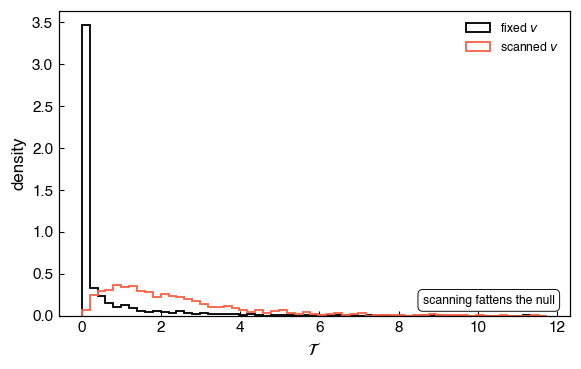

In [10]:
# (2) fixed-v vs scanned-v null. Same template, noise, band -- only the scan
#     differs.
null = mc.run_null_mc(sigma_pix3, N3, dv3, v_grid, n_draws=1500, seed=11,
                      sigma_ft=sigma_ft3, template=template, zeta_max=zeta_max3)
T_scan = null["T"]

rng3 = np.random.default_rng(99)
T_fixed = np.array([
    detect.detection_statistic(template + rng3.normal(0, sigma_pix3, N3), dv3,
                               np.array([70.0]), sigma_ft=sigma_ft3,
                               zeta_max=zeta_max3)["T"]
    for _ in range(1500)])

print(f"fixed v:    w = P(T<=0) = {np.mean(T_fixed <= 0):.3f}   (Chernoff: 0.5)")
print(f"scanned v:  w = P(T<=0) = {np.mean(T_scan <= 0):.3f}   "
     f"(the {len(v_grid)}-point scan almost always finds SOME "
     "positive-alpha trial)")

fig, ax = plt.subplots(figsize=(6.0, 3.6))
bins = np.linspace(0, np.quantile(T_scan, 0.999), 60)
ax.hist(T_fixed, bins=bins, density=True, histtype="step", color="k",
        lw=1.2, label="fixed $v$")
ax.hist(T_scan, bins=bins, density=True, histtype="step", color="tomato",
        lw=1.2, label="scanned $v$")
ax.set_xlabel(r"$\mathcal{T}$"); ax.set_ylabel("density")
ax.legend(frameon=False)
regime_label(ax, "scanning fattens the null", loc="lower right")
plt.show()

In [11]:
# (3) Gamma calibration -> threshold -> the cost of using the wrong one.
fit = nulls.fit_gamma_null(T_scan)
thr_cal = nulls.gamma_null_threshold(0.05, fit["a"], fit["theta"], fit["w0"])
thr_naive = nulls.detection_threshold(0.05, df=1)
print(f"Gamma fit: w={fit['w0']:.3f}  a={fit['a']:.2f}  theta={fit['theta']:.2f}  "
     f"KS D={fit['ks_stat']:.3f}")
print("(KS D only; the KS p-value is invalid with estimated parameters "
     "[Lilliefors] and is never quoted)\n")
print(f"calibrated threshold: {thr_cal:.2f}   naive fixed-v: {thr_naive:.2f}\n")

print(f"{'alpha':>6} {'completeness @ calibrated':>26} {'@ naive 2.706':>14}")
for a_inj in (0.03, 0.10, 0.20):
    inj = mc.run_injection_mc(alpha=a_inj, dv_true=60.0, sigma_pix=sigma_pix3,
                              n_pix=N3, dv=dv3, v_grid=v_grid, n_draws=400,
                              seed=3, template=template, sigma_ft=sigma_ft3,
                              zeta_max=zeta_max3)
    print(f"{a_inj:>6.2f} {mc.completeness(inj['T'], thr_cal):>26.3f} "
         f"{mc.completeness(inj['T'], thr_naive):>14.3f}")

Gamma fit: w=0.000  a=1.81  theta=1.23  KS D=0.022
(KS D only; the KS p-value is invalid with estimated parameters [Lilliefors] and is never quoted)

calibrated threshold: 5.45   naive fixed-v: 2.71

 alpha  completeness @ calibrated  @ naive 2.706


  0.03                      0.080          0.360


  0.10                      0.375          0.685


  0.20                      0.912          0.980


At $\alpha=0.03$ the naive threshold reports 4.5 times the true completeness,
0.36 against 0.08 — detection power near the false-alarm floor, dressed up as
solid sensitivity. This exact mistake was caught in review of this package's own
code. The calibrated threshold is not an optional refinement.

In [12]:
# (4) the p_emp floor: rank p-values cannot resolve below 1/(N+1).
inj_strong = mc.run_injection_mc(alpha=0.4, dv_true=60.0, sigma_pix=sigma_pix3,
                                 n_pix=N3, dv=dv3, v_grid=v_grid, n_draws=1,
                                 seed=1, template=template, sigma_ft=sigma_ft3,
                                 zeta_max=zeta_max3)
T_obs = inj_strong["T"][0]
p_rank = mc.p_emp(T_obs, T_scan)
p_tail = nulls.gamma_null_pvalue(T_obs, fit["a"], fit["theta"], fit["w0"])
floor = 1.0 / (len(T_scan) + 1)
print(f"observed T = {T_obs:.1f}   (strong injection)")
print(f"rank p_emp = {p_rank:.5f}  vs floor 1/(N+1) = {floor:.5f}"
     f"   -> SATURATED: report as a bound, p <= {floor:.1e}")
print(f"Gamma tail = {p_tail:.2e}  -> an EXTRAPOLATION past every simulated "
     "draw; quote only alongside the rank bound")

observed T = 37.5   (strong injection)
rank p_emp = 0.00067  vs floor 1/(N+1) = 0.00067   -> SATURATED: report as a bound, p <= 6.7e-04
Gamma tail = 9.93e-13  -> an EXTRAPOLATION past every simulated draw; quote only alongside the rank bound


In [13]:
# (5) red noise: AR(1) pixel noise (correlation length 5 km/s) inflates the
#     Gamma scale theta above the chi2 value 2 -- the mechanism behind
#     real-spectrum null widths (the high-zeta noise estimate under-reports
#     the fit-band noise when the noise is red).
dv4, N4 = 1.0, 512
vg4 = np.arange(-150.0, 151.0, 15.0)
sft4 = amplitude.amp_noise_sigma(0.02, n=N4)
T_w = mc.run_null_mc(0.02, N4, dv4, vg4, 600, seed=7, noise="white",
                     sigma_ft=sft4)["T"]
T_r = mc.run_null_mc(0.02, N4, dv4, vg4, 600, seed=7, noise=("ar1", 5.0),
                     sigma_ft=sft4)["T"]
print(f"white noise:       theta = {nulls.fit_gamma_null(T_w)['theta']:.2f}"
     "   (~ chi2-like)")
print(f"AR(1), l_corr=5:   theta = {nulls.fit_gamma_null(T_r)['theta']:.2f}"
     "   (inflated)")

white noise:       theta = 0.99   (~ chi2-like)
AR(1), l_corr=5:   theta = 5.71   (inflated)


In [14]:
# (6) the static-blend effect: give H0 a line it CANNOT fully absorb -- a
#     resolved rotating profile against the 2-term polynomial baseline --
#     and the null inflates wholesale. Adding the zeta^4 baseline column
#     (n_baseline=4), which notebook 01 showed carries the leading
#     rotational term, absorbs most of it back.
tmpl_rot = mc.make_template(dv3, N3, line_depth=0.20, vG=12.0, gamma=3.0,
                            vsini=60.0)
rows = [("absorbable line (vsini=0), n_baseline=2", template, 2),
        ("rotating line (vsini=60),  n_baseline=2", tmpl_rot, 2),
        ("rotating line (vsini=60),  n_baseline=4", tmpl_rot, 4)]
print(f"{'H0 template / model':>42} {'median T':>9} {'95th pct':>9}")
for name, tp, nb in rows:
    Tn = mc.run_null_mc(sigma_pix3, N3, dv3, v_grid, n_draws=300, seed=33,
                        sigma_ft=sigma_ft3, template=tp, zeta_max=zeta_max3,
                        n_baseline=nb)["T"]
    print(f"{name:>42} {np.median(Tn):>9.2f} {np.quantile(Tn, 0.95):>9.2f}")

                       H0 template / model  median T  95th pct


   absorbable line (vsini=0), n_baseline=2      1.55      7.34


   rotating line (vsini=60),  n_baseline=2     34.83     74.47


   rotating line (vsini=60),  n_baseline=4      7.71     20.31


The rotating profile inflates the null median about twenty-fold: the scan finds
a "companion" that mimics the rotational curvature the baseline could not
absorb. This is the §3.2 point of the paper. A static feature the single-star
model cannot fit is a genuine departure from the isolated-single-line null and
$T$ is right to flag it; what separates it from a real orbiting companion is its
behaviour across epochs. It is also why `mc.make_template` defaults to
$v\sin i=0$, and why the demonstrations in this section use a fully absorbable
line: anything $H_0$ misfits becomes part of the null, and has to be either
modelled — here, with the $\zeta^4$ column — or calibrated in.

Three rules carry over to real data. Keep the Monte Carlo and the fit mechanically
identical: same `v_grid`, same `zeta_max` or `snr_cutoff`, same `sigma_ft` in
`run_null_mc` as in the data fit. The signatures force you to pass all of them
explicitly for that reason. Measure `sigma_ft` from a line-free window of your
own spectra, and if the noise is red, expect the behaviour shown above — calibrate
it rather than assuming $\chi^2$. And quote the rank floor next to any parametric
tail p-value, always.

That closes the set: the Fourier structure of a single star, the amplitude and
phase signatures of a companion, and a detection statistic with a null you can
defend. Applying the same machinery to a survey — efficiency maps, and an
exclusion region on the HR diagram built from model atmospheres — is a separate
piece of work and is not included here.